# 02 · The Apprentices — Bag-of-Words Baselines

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Cecile1015/emotion-mirror-cbs4702/blob/main/notebooks/02_baselines.ipynb)

This notebook trains the three baselines of the project. They form the first rung of the representation ladder: each text is reduced to a bag of words, and later notebooks replace this representation with n-grams, word embeddings and contextual encoders.

| Model id | Representation (L6) | Classifier (L5) | Tuned on validation |
|---|---|---|---|
| `bow_nb` | Bag of words — raw counts (`CountVectorizer`) | Multinomial Naive Bayes (generative) | smoothing `alpha` |
| `bow_lr` | Bag of words — raw counts (`CountVectorizer`) | Multinomial logistic regression / softmax (discriminative) | inverse regularisation strength `C` |
| `tfidf_lr` | TF-IDF weights (`TfidfVectorizer`) | Multinomial logistic regression / softmax (discriminative) | `C` |

The design isolates two **controlled comparisons**, each changing a single factor:

* `bow_nb` → `bow_lr`: same features, **generative vs. discriminative** classifier.
* `bow_lr` → `tfidf_lr`: same classifier, **raw counts vs. TF-IDF** weighting.

**Experimental protocol** (shared by every notebook): models are fitted on the training split; hyper-parameters are chosen by **macro-F1 on the validation split**; the test split is used once, for the final evaluation, through `src/evaluate.py`. Random seed: 42.

| § | Content |
|---|---|
| 1 | Data |
| 2 | Representations and the three pipelines |
| 3 | Hyper-parameter selection on the validation set |
| 4 | Final training, test evaluation and saved artefacts |
| 5 | Results: summary table, per-class F1, confusion matrices, significance tests, calibration |
| 6 | Inside the models: highest-weighted words per emotion |
| 7 | Discussion |

In [1]:
# Environment setup: runs locally (from the project root or notebooks/) and on Google Colab.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/Cecile1015/emotion-mirror-cbs4702.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Colab already provides every package this notebook needs; only the repository is cloned.
    ROOT = Path("/content/emotion-mirror-cbs4702")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    os.chdir(ROOT / "notebooks")
else:
    ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT} | running on Colab: {IN_COLAB}")

Project root: /Users/yin/Desktop/6-polyu year3 semester1/CBS4702 Advanced Topics in Quantitative Language Studies/emotion-mirror-cbs4702 | running on Colab: False


In [2]:
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, log_loss
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

from src.config import EMOTION_COLORS, FIG_DIR, LABELS, METRICS_DIR, MODELS_DIR, SEED, ensure_dirs, set_seed
from src.data import load_splits
from src.evaluate import (
    mcnemar_test,
    evaluate,
    paired_bootstrap,
    plot_confusion_matrix,
    plot_per_class_f1,
    summary_table,
)

set_seed(SEED)
ensure_dirs()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "axes.titleweight": "bold"})
pd.set_option("display.max_colwidth", 120)

# All classical (scikit-learn) models of the project share this folder.
CLASSICAL_DIR = MODELS_DIR / "classical"
CLASSICAL_DIR.mkdir(parents=True, exist_ok=True)
LABEL_IDS = list(range(len(LABELS)))
print(f"scikit-learn {sklearn.__version__}")


def savefig(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches="tight")


def macro_f1(y_true, y_pred):
    """Primary selection metric: unweighted mean of the six per-class F1 scores."""
    return f1_score(y_true, y_pred, labels=LABEL_IDS, average="macro", zero_division=0)

scikit-learn 1.9.1


## 1. Data

The official splits are loaded from the local cache created in `01_eda` (train 16,000 / validation 2,000 / test 2,000). The input is the raw `text` column; the dataset is already lower-cased and stripped of punctuation, so no further preprocessing is applied.

In [3]:
splits = load_splits()
train, val, test = splits["train"], splits["validation"], splits["test"]

X_train, y_train = train["text"].tolist(), train["label"].to_numpy()
X_val, y_val = val["text"].tolist(), val["label"].to_numpy()
X_test, y_test = test["text"].tolist(), test["label"].to_numpy()

for name, y in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:<11} n = {len(y):>6,}")

train       n = 16,000
validation  n =  2,000
test        n =  2,000


## 2. Representations and pipelines

### 2.1 Bag of words and TF-IDF (Lecture 6)

A **bag-of-words** model represents a document by the multiset of its words and discards word order. `CountVectorizer` builds a vocabulary from the training texts and maps each document to a vector of term counts $\mathrm{tf}(t, d)$; the result is a sparse document-term matrix.

**TF-IDF** rescales each count by how informative the term is across the collection. With scikit-learn's default (smoothed) formula,

$$
\mathrm{idf}(t) = \ln\frac{1 + N}{1 + \mathrm{df}(t)} + 1, \qquad
\text{tf-idf}(t, d) = \mathrm{tf}(t, d)\cdot \mathrm{idf}(t),
$$

where $N$ is the number of documents and $\mathrm{df}(t)$ the number of documents containing $t$. Each row is then L2-normalised, so that long and short texts lie on the same unit sphere.

### 2.2 The three pipelines

Each baseline is a scikit-learn `Pipeline` of a vectoriser and a classifier, so that the vocabulary and idf statistics are estimated **on the training split only** and are re-applied unchanged to the validation and test texts. A saved pipeline can be applied directly to raw strings, which the web service will use later.

The vectorisers keep their default settings (lower-casing, unigrams, no stop-word removal). The default token pattern keeps only tokens of two or more characters, so the pronoun *i* is not part of the vocabulary. Stop words are kept on purpose: the English stop-word list contains negators such as *not* and *no*, which matter for emotion. N-grams, character n-grams and class weights are deliberately left to Improvement 1, so that each step of the ladder changes one thing at a time.

* **Multinomial Naive Bayes** (generative) models the joint probability $P(c, d) = P(c)\prod_{t \in d} P(t \mid c)$ and predicts with Bayes' rule. The word probabilities use additive (Lidstone) smoothing, $\hat P(t \mid c) = \dfrac{\mathrm{count}(t, c) + \alpha}{\sum_{t'} \mathrm{count}(t', c) + \alpha |V|}$; $\alpha = 1$ is Laplace smoothing.
* **Multinomial logistic regression** (discriminative) models the conditional probability directly with the softmax function, $P(c \mid \mathbf{x}) = \dfrac{\exp(\mathbf{w}_c^\top \mathbf{x} + b_c)}{\sum_{k}\exp(\mathbf{w}_k^\top \mathbf{x} + b_k)}$, and is trained by minimising the cross-entropy loss plus an L2 penalty $\frac{1}{2C}\lVert W \rVert^2$. A smaller $C$ means stronger regularisation. With the default `lbfgs` solver, scikit-learn fits a single softmax model over the six classes rather than six one-vs-rest models. The convergence tolerance is tightened from the default `1e-4` to `1e-6`: the L2-penalised objective is strictly convex and has a unique optimum, but with the default tolerance the optimiser stops before reaching it, at a point that depends on the library versions. With `1e-6` the results no longer change when the tolerance is tightened further, so they are reproducible across machines.

In [4]:
BASELINES = {
    "bow_nb": Pipeline([
        ("vec", CountVectorizer()),
        ("clf", MultinomialNB()),
    ]),
    "bow_lr": Pipeline([
        ("vec", CountVectorizer()),
        ("clf", LogisticRegression(tol=1e-6, max_iter=5000, random_state=SEED)),
    ]),
    "tfidf_lr": Pipeline([
        ("vec", TfidfVectorizer()),
        ("clf", LogisticRegression(tol=1e-6, max_iter=5000, random_state=SEED)),
    ]),
}

DISPLAY_NAMES = {"bow_nb": "BoW + NB", "bow_lr": "BoW + LR", "tfidf_lr": "TF-IDF + LR"}

# Vocabulary learned from the training split (identical for both vectorisers).
vocab_size = len(clone(BASELINES["bow_lr"].named_steps["vec"]).fit(X_train).vocabulary_)
print(f"Vocabulary size |V| = {vocab_size:,} unigram types (tokens of >= 2 characters)")

# idf of selected terms on the training split: frequent words receive low idf, rare emotion words high idf.
train_tfidf = clone(BASELINES["tfidf_lr"].named_steps["vec"]).fit(X_train)
idf = pd.Series(train_tfidf.idf_, index=train_tfidf.get_feature_names_out())
example_terms = ["feel", "feeling", "and", "not", "happy", "sad", "amazed", "sympathetic"]
display(idf[example_terms].round(2).rename("idf").to_frame().T)
print(f"idf range on the training split: {idf.min():.2f} (most frequent term '{idf.idxmin()}') to {idf.max():.2f}")

Vocabulary size |V| = 15,186 unigram types (tokens of >= 2 characters)


,feel,feeling,and,not,happy,sad,amazed,sympathetic
idf,1.41,2.17,1.82,3.26,5.22,5.86,6.42,6.67


idf range on the training split: 1.41 (most frequent term 'feel') to 9.99


*feel* occurs in almost every text (97.3% contain a form of it; 01_eda §6) and therefore receives the lowest idf in the whole vocabulary (1.41), whereas rare emotion words such as *amazed* (6.42) receive values more than four times larger. After TF-IDF weighting, the template word carries much less weight than the words that actually signal an emotion.

## 3. Hyper-parameter selection on the validation set

Each pipeline is fitted on the training split for every value of a log-spaced grid and scored on the validation split. The test split is not touched in this section.

* **Selection rule:** highest validation macro-F1. If two settings tie, the more strongly regularised one is kept (larger `alpha`, smaller `C`), because it is the simpler model.
* Training macro-F1 is recorded as well, so that under- and over-fitting are visible in the validation curves (§3.2).

The complete search log is saved to `results/metrics/tuning_baselines_validation.csv`.

In [5]:
SEARCH_SPACE = {
    "bow_nb": ("clf__alpha", [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]),
    "bow_lr": ("clf__C", [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0]),
    "tfidf_lr": ("clf__C", [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0]),
}


def tune_on_validation(name, base_pipeline, param, grid):
    """Fit one pipeline per grid value on train and score it on validation."""
    rows = []
    for value in grid:
        model = clone(base_pipeline).set_params(**{param: value})
        start = time.perf_counter()
        model.fit(X_train, y_train)
        fit_seconds = time.perf_counter() - start
        val_pred = model.predict(X_val)
        rows.append({
            "model": name,
            "param": param.split("__")[1],
            "value": value,
            "train_macro_f1": macro_f1(y_train, model.predict(X_train)),
            "val_accuracy": float(np.mean(val_pred == y_val)),
            "val_macro_f1": macro_f1(y_val, val_pred),
            "fit_seconds": fit_seconds,
        })
    return pd.DataFrame(rows)


def select_best(log):
    """Highest validation macro-F1; ties go to the more strongly regularised model."""
    param = log["param"].iloc[0]
    # For C, small values regularise more; for alpha, large values smooth more.
    ordered = log.sort_values("value", ascending=(param == "C")).reset_index(drop=True)
    return ordered.loc[ordered["val_macro_f1"].idxmax()]


search_logs = {}
for name, pipeline in BASELINES.items():
    param, grid = SEARCH_SPACE[name]
    search_logs[name] = tune_on_validation(name, pipeline, param, grid)

tuning_log = pd.concat(search_logs.values(), ignore_index=True)
tuning_log.to_csv(METRICS_DIR / "tuning_baselines_validation.csv", index=False)
display(tuning_log.round(4))

,model,param,value,train_macro_f1,val_accuracy,val_macro_f1,fit_seconds
0,bow_nb,alpha,0.01,0.9617,0.7285,0.6653,0.0666
1,bow_nb,alpha,0.03,0.9620,0.7505,0.6860,0.0657
2,bow_nb,alpha,0.10,0.9573,0.7845,0.7122,0.0672
3,bow_nb,alpha,0.30,0.9309,0.8075,0.7187,0.0634
4,bow_nb,alpha,1.00,0.7670,0.7615,0.6016,0.0628
5,bow_nb,alpha,3.00,0.4456,0.6445,0.3765,0.0626
6,bow_lr,C,0.01,0.3494,0.5915,0.3177,0.4026
7,bow_lr,C,0.03,0.6776,0.7465,0.5788,0.5763
8,bow_lr,C,0.10,0.9073,0.8580,0.8011,0.8443
9,bow_lr,C,0.30,0.9569,0.8845,0.8441,1.0893


### 3.1 Selected hyper-parameters

In [6]:
best_params = {}
selection_rows = []
for name, log in search_logs.items():
    best = select_best(log)
    param_path = SEARCH_SPACE[name][0]
    best_params[name] = {param_path: float(best["value"])}
    selection_rows.append({
        "model": name,
        "hyper-parameter": best["param"],
        "selected value": best["value"],
        "val macro-F1": best["val_macro_f1"],
        "val accuracy": best["val_accuracy"],
        "train macro-F1": best["train_macro_f1"],
        "grid": ", ".join(f"{v:g}" for v in SEARCH_SPACE[name][1]),
    })

selection = pd.DataFrame(selection_rows).set_index("model")
display(selection.round(4))

,hyper-parameter,selected value,val macro-F1,val accuracy,train macro-F1,grid
model,,,,,,
bow_nb,alpha,0.3,0.7187,0.8075,0.9309,"0.01, 0.03, 0.1, 0.3, 1, 3"
bow_lr,C,10.0,0.8564,0.8890,0.9949,"0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100"
tfidf_lr,C,30.0,0.8650,0.8945,0.9945,"0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100"


### 3.2 Validation curves

The gap between the training and validation curves shows the bias–variance trade-off controlled by each hyper-parameter. For logistic regression, a very small `C` under-fits (both curves low); a very large `C` lets the weights grow until the model nearly memorises the training texts, and validation performance stops improving. For Naive Bayes, a very small `alpha` trusts rare word counts too much, while a very large `alpha` flattens every $P(t \mid c)$ towards the uniform distribution.

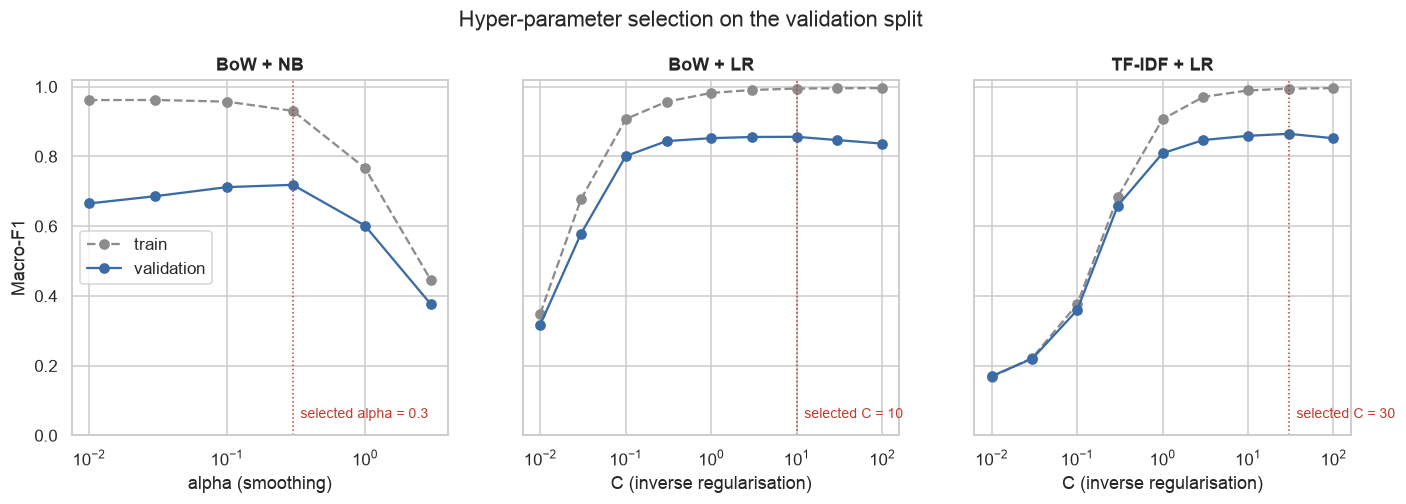

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (name, log) in zip(axes, search_logs.items()):
    param = log["param"].iloc[0]
    ax.plot(log["value"], log["train_macro_f1"], "o--", color="0.55", label="train")
    ax.plot(log["value"], log["val_macro_f1"], "o-", color="#3B6BA5", label="validation")
    chosen = best_params[name][SEARCH_SPACE[name][0]]
    ax.axvline(chosen, color="#C0392B", lw=1, ls=":")
    ax.annotate(f"selected {param} = {chosen:g}", xy=(chosen, 0.05), xytext=(5, 0),
                textcoords="offset points", color="#C0392B", fontsize=9)
    ax.set_xscale("log")
    ax.set_xlabel(param + (" (smoothing)" if param == "alpha" else " (inverse regularisation)"))
    ax.set_title(DISPLAY_NAMES[name])
    ax.set_ylim(0, 1.02)
axes[0].set_ylabel("Macro-F1")
axes[0].legend(loc="center left")
fig.suptitle("Hyper-parameter selection on the validation split", y=1.03)
savefig(fig, "baselines_validation_curves.png")
plt.show()

## 4. Final training and test evaluation

Each pipeline is refitted on the training split with its selected hyper-parameter (the validation split is **not** added to the training data, so that every model in the project is trained on exactly the same 16,000 texts). The model is then scored through `src/evaluate.py`:

* on **validation** — this row joins the dummy baselines from `01_eda` in the model-selection table (The Ledger);
* on **test** — the final, reported score.

For each split the evaluator writes `results/metrics/<model>__<split>.json` and `results/predictions/<model>__<split>.csv` (text, gold label, prediction and the six class probabilities). The fitted pipeline is saved with `joblib` to `models/classical/<model>.joblib`.

In [8]:
final_models = {}
val_preds, test_preds, test_probas = {}, {}, {}

for name, base_pipeline in BASELINES.items():
    params = best_params[name]
    model = clone(base_pipeline).set_params(**params).fit(X_train, y_train)
    final_models[name] = model

    param_text = ", ".join(f"{k.split('__')[1]}={v:g}" for k, v in params.items())
    vec_name = type(model.named_steps["vec"]).__name__
    clf_name = type(model.named_steps["clf"]).__name__
    notes = f"{vec_name} (unigrams, default settings) + {clf_name} ({param_text}); selected by validation macro-F1"

    for split, X, y, store in [("validation", X_val, y_val, val_preds), ("test", X_test, y_test, test_preds)]:
        pred = model.predict(X)
        proba = model.predict_proba(X)
        evaluate(name, y, pred, split=split, y_proba=proba, texts=X, notes=notes)
        store[name] = pred
        if split == "test":
            test_probas[name] = proba

    joblib.dump(model, CLASSICAL_DIR / f"{name}.joblib")

print("\nSaved models:", sorted(p.name for p in CLASSICAL_DIR.glob("*.joblib")))

bow_nb [validation]  accuracy=0.8075  macro-F1=0.7187  weighted-F1=0.7990
bow_nb [test]  accuracy=0.8015  macro-F1=0.6949  weighted-F1=0.7918
bow_lr [validation]  accuracy=0.8890  macro-F1=0.8564  weighted-F1=0.8887
bow_lr [test]  accuracy=0.8830  macro-F1=0.8313  weighted-F1=0.8825
tfidf_lr [validation]  accuracy=0.8945  macro-F1=0.8650  weighted-F1=0.8936
tfidf_lr [test]  accuracy=0.8815  macro-F1=0.8320  weighted-F1=0.8801

Saved models: ['bow_lr.joblib', 'bow_nb.joblib', 'tfidf_lr.joblib']


In [9]:
# Sanity check: a reloaded pipeline accepts raw strings and reproduces the saved predictions.
reloaded = joblib.load(CLASSICAL_DIR / "tfidf_lr.joblib")
assert np.array_equal(reloaded.predict(X_test), test_preds["tfidf_lr"])

demo = ["i feel so lonely without you", "i am thrilled about the trip", "i was shocked by the news"]
demo_proba = pd.DataFrame(reloaded.predict_proba(demo), columns=LABELS, index=demo).round(3)
demo_proba["prediction"] = [LABELS[i] for i in reloaded.predict(demo)]
demo_proba

,sadness,joy,love,anger,fear,surprise,prediction
i feel so lonely without you,0.988,0.003,0.002,0.007,0.001,0.000,sadness
i am thrilled about the trip,0.000,0.998,0.000,0.000,0.001,0.000,joy
i was shocked by the news,0.000,0.000,0.000,0.000,0.001,0.999,surprise


## 5. Results

### 5.1 Summary tables

The validation table repeats the trivial classifiers from `01_eda` as a performance floor. The test table adds a 95% bootstrap confidence interval for macro-F1 (1,000 resamples of the 2,000 test texts), which shows how much of a difference between models could arise from the particular test sample.

In [10]:
BASELINE_IDS = list(BASELINES)

print("Validation split (used for model selection)")
display(summary_table(["dummy_most_frequent", "dummy_stratified"] + BASELINE_IDS, split="validation").round(3))


def bootstrap_ci(y_true, y_pred, n_boot=1000, seed=SEED):
    """Percentile 95% confidence interval of macro-F1 over resampled test sets."""
    rng = np.random.default_rng(seed)
    n = len(y_true)
    scores = [macro_f1(y_true[idx], y_pred[idx]) for idx in (rng.integers(0, n, n) for _ in range(n_boot))]
    return np.percentile(scores, [2.5, 97.5])


test_table = summary_table(BASELINE_IDS, split="test")
ci = {name: bootstrap_ci(y_test, test_preds[name]) for name in BASELINE_IDS}
test_table.insert(2, "macro_f1_ci95", [f"[{ci[n][0]:.3f}, {ci[n][1]:.3f}]" for n in BASELINE_IDS])

print("Test split (final evaluation)")
display(test_table.round(3))

Validation split (used for model selection)


,accuracy,macro_f1,weighted_f1,f1_sadness,f1_joy,f1_love,f1_anger,f1_fear,f1_surprise
model,,,,,,,,,
dummy_most_frequent,0.352,0.087,0.183,0.000,0.521,0.000,0.000,0.000,0.000
dummy_stratified,0.244,0.171,0.244,0.297,0.349,0.092,0.144,0.094,0.052
bow_nb,0.808,0.719,0.799,0.841,0.860,0.689,0.789,0.751,0.382
bow_lr,0.889,0.856,0.889,0.909,0.923,0.816,0.893,0.819,0.778
tfidf_lr,0.894,0.865,0.894,0.912,0.924,0.826,0.897,0.834,0.797


Test split (final evaluation)


,accuracy,macro_f1,macro_f1_ci95,weighted_f1,f1_sadness,f1_joy,f1_love,f1_anger,f1_fear,f1_surprise
model,,,,,,,,,,
bow_nb,0.802,0.695,"[0.667, 0.722]",0.792,0.843,0.858,0.595,0.781,0.733,0.360
bow_lr,0.883,0.831,"[0.808, 0.854]",0.882,0.927,0.911,0.741,0.880,0.842,0.688
tfidf_lr,0.882,0.832,"[0.808, 0.853]",0.880,0.919,0.910,0.761,0.876,0.833,0.694


### 5.2 Per-class F1 and confusion matrices

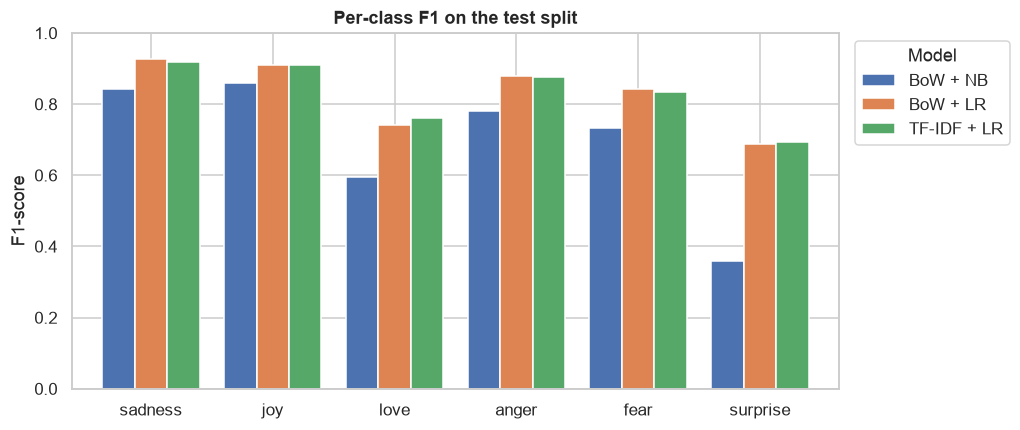

,sadness,joy,love,anger,fear,surprise
test support,581,695,159,275,224,66


In [11]:
ax = plot_per_class_f1(
    test_table.rename(index=DISPLAY_NAMES),
    title="Per-class F1 on the test split",
    save_as="baselines_per_class_f1.png",
)
plt.show()

support = pd.Series(np.bincount(y_test, minlength=len(LABELS)), index=LABELS, name="test support")
display(support.to_frame().T)

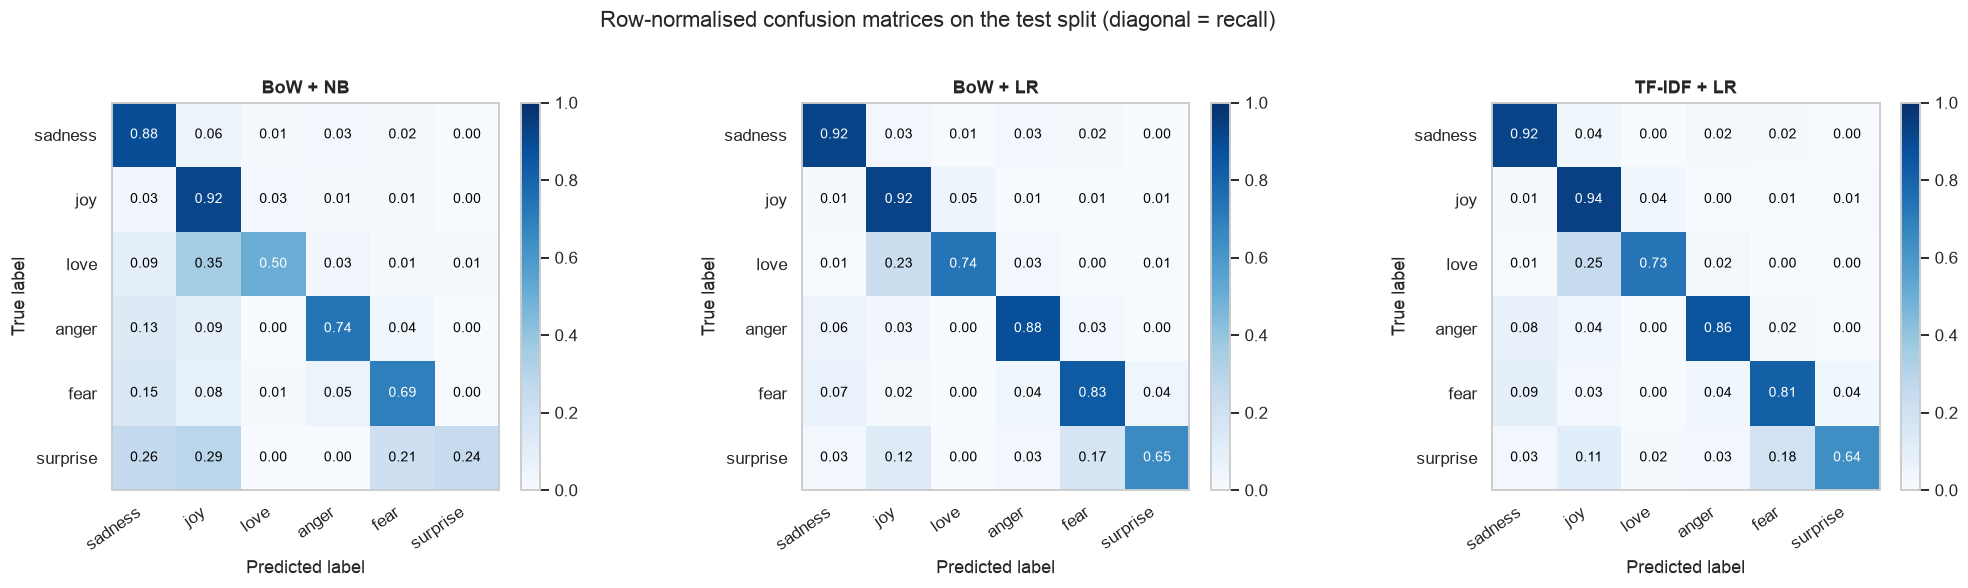

BoW + NB     love→joy 35%, surprise→joy 29%, surprise→sadness 26%, surprise→fear 21%
BoW + LR     love→joy 23%, surprise→fear 17%, surprise→joy 12%, fear→sadness 7%
TF-IDF + LR  love→joy 25%, surprise→fear 18%, surprise→joy 11%, fear→sadness 9%


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
for ax, name in zip(axes, BASELINE_IDS):
    plot_confusion_matrix(y_test, test_preds[name], title=DISPLAY_NAMES[name], ax=ax)
fig.suptitle("Row-normalised confusion matrices on the test split (diagonal = recall)", y=1.02)
fig.tight_layout()
savefig(fig, "baselines_confusion_matrices.png")
plt.show()


def top_confusions(y_true, y_pred, k=4):
    """The k largest off-diagonal cells, as a share of the gold class."""
    cm = pd.crosstab(pd.Series(y_true, name="gold"), pd.Series(y_pred, name="pred"), normalize="index")
    pairs = cm.stack().reset_index(name="share")
    pairs = pairs[pairs["gold"] != pairs["pred"]].nlargest(k, "share")
    return ", ".join(f"{LABELS[g]}→{LABELS[p]} {s:.0%}" for g, p, s in pairs.itertuples(index=False))


for name in BASELINE_IDS:
    print(f"{DISPLAY_NAMES[name]:<12} {top_confusions(y_test, test_preds[name])}")

### 5.3 Significance of the two controlled comparisons

Both comparisons are evaluated on the same 2,000 test texts, so paired tests are used:

* **McNemar's test** compares the counts of texts that only one of the two models classifies correctly ($b$: only A correct, $c$: only B correct). It tests accuracy-level disagreement.
* The **paired bootstrap** resamples the test set and recomputes macro-F1 of both models on every resample; the 95% interval of the difference $\Delta = \text{F1}_B - \text{F1}_A$ shows whether the improvement in the primary metric is robust.

In [13]:
COMPARISONS = [
    ("bow_nb", "bow_lr", "generative → discriminative (same BoW features)"),
    ("bow_lr", "tfidf_lr", "raw counts → TF-IDF (same LR classifier)"),
]

rows = []
for a, b, question in COMPARISONS:
    mc = mcnemar_test(y_test, test_preds[a], test_preds[b])
    bs = paired_bootstrap(y_test, test_preds[a], test_preds[b], n_boot=2000, seed=SEED)
    rows.append({
        "comparison (A → B)": f"{DISPLAY_NAMES[a]} → {DISPLAY_NAMES[b]}",
        "question": question,
        "b (only A correct)": mc["b"],
        "c (only B correct)": mc["c"],
        "McNemar p": mc["p_value"],
        "Δ macro-F1": bs["delta"],
        "95% CI of Δ": f"[{bs['ci_low']:+.3f}, {bs['ci_high']:+.3f}]",
    })

significance = pd.DataFrame(rows).set_index("comparison (A → B)")
significance.to_csv(METRICS_DIR / "significance_baselines_test.csv")
display(significance.style.format({"McNemar p": "{:.2g}", "Δ macro-F1": "{:+.3f}"}))

,question,b (only A correct),c (only B correct),McNemar p,Δ macro-F1,95% CI of Δ
comparison (A → B),,,,,,
BoW + NB → BoW + LR,generative → discriminative (same BoW features),75,238,5.3e-20,+0.136,"[+0.105, +0.169]"
BoW + LR → TF-IDF + LR,raw counts → TF-IDF (same LR classifier),38,35,0.81,+0.001,"[-0.013, +0.014]"


### 5.4 Probability quality

Accuracy and F1 only use the arg-max label. The web application will also display the class probabilities, so their quality matters: the **log-loss** (cross-entropy on the test set) penalises confident mistakes, and the mean confidence on wrong predictions shows how often a model is sure and wrong.

In [14]:
calibration_rows = []
for name in BASELINE_IDS:
    proba = test_probas[name]
    confidence = proba.max(axis=1)
    correct = test_preds[name] == y_test
    calibration_rows.append({
        "model": DISPLAY_NAMES[name],
        "test log-loss": log_loss(y_test, proba, labels=LABEL_IDS),
        "accuracy": correct.mean(),
        "mean confidence": confidence.mean(),
        "mean confidence (wrong)": confidence[~correct].mean(),
        "wrong with confidence > 0.9": int(np.sum(~correct & (confidence > 0.9))),
    })
display(pd.DataFrame(calibration_rows).set_index("model").round(3))

,test log-loss,accuracy,mean confidence,mean confidence (wrong),wrong with confidence > 0.9
model,,,,,
BoW + NB,0.659,0.802,0.840,0.696,72
BoW + LR,0.334,0.883,0.913,0.735,59
TF-IDF + LR,0.329,0.882,0.869,0.666,33


## 6. Inside the models: highest-weighted words per emotion

A linear model is interpretable because each class score is a weighted sum of word features. For logistic regression the weight $w_{c,t}$ is the change in the log-odds score of class $c$ when term $t$ occurs once more (or, for TF-IDF, when its weight increases by one unit). The figure shows the ten words with the largest positive weight for each emotion in the TF-IDF model.

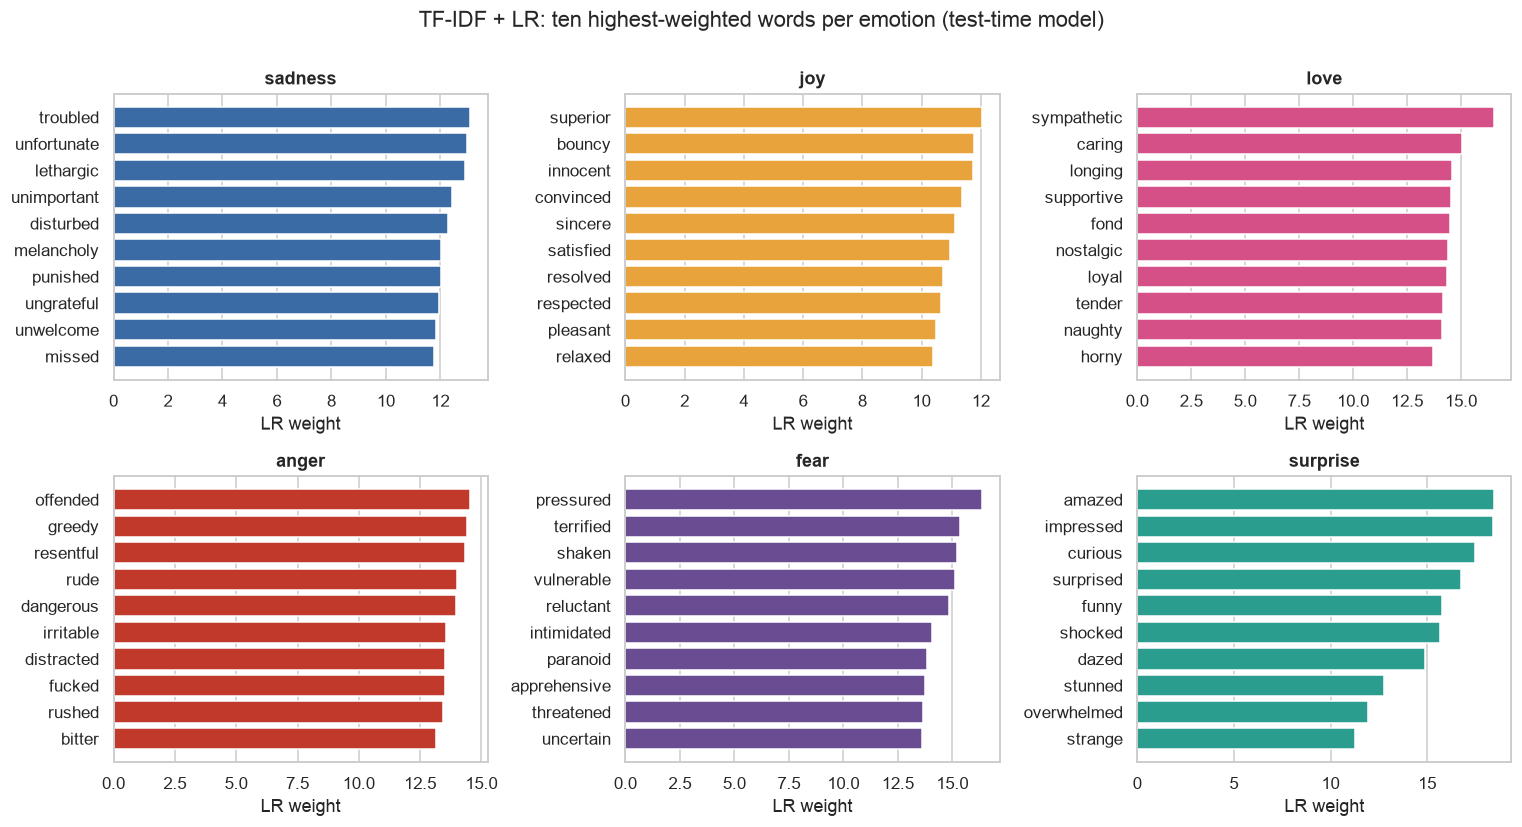

In [15]:
def top_lr_words(pipeline, k=10):
    """Return {label: [(word, weight), ...]} with the k largest softmax weights per class."""
    vocab = pipeline.named_steps["vec"].get_feature_names_out()
    W = pipeline.named_steps["clf"].coef_  # shape (n_classes, |V|)
    return {
        label: [(vocab[j], W[c, j]) for j in np.argsort(W[c])[::-1][:k]]
        for c, label in enumerate(LABELS)
    }


tfidf_top = top_lr_words(final_models["tfidf_lr"], k=10)

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, label in zip(axes.ravel(), LABELS):
    words, weights = zip(*tfidf_top[label][::-1])
    ax.barh(words, weights, color=EMOTION_COLORS[label])
    ax.set_title(label)
    ax.set_xlabel("LR weight")
    ax.grid(axis="y", visible=False)
fig.suptitle("TF-IDF + LR: ten highest-weighted words per emotion (test-time model)", y=1.0)
fig.tight_layout()
savefig(fig, "baselines_lr_top_weights.png")
plt.show()

The table below contrasts what the generative and discriminative models learn. For Naive Bayes, the most probable words under $P(t \mid c)$ describe what a text of class $c$ *looks like*, and they are dominated by function words that are frequent in every class. Centring the log-probabilities across classes, $\log P(t \mid c) - \frac{1}{6}\sum_{k}\log P(t \mid k)$, gives the words that best *distinguish* class $c$ — the quantity that logistic regression optimises directly.

In [16]:
def top_nb_words(pipeline, k=8, centred=True):
    """Top words per class from the Naive Bayes log-probabilities log P(t | c)."""
    vocab = pipeline.named_steps["vec"].get_feature_names_out()
    log_prob = pipeline.named_steps["clf"].feature_log_prob_
    scores = log_prob - log_prob.mean(axis=0, keepdims=True) if centred else log_prob
    return {label: [vocab[j] for j in np.argsort(scores[c])[::-1][:k]] for c, label in enumerate(LABELS)}


K = 8
nb_raw = top_nb_words(final_models["bow_nb"], K, centred=False)
nb_centred = top_nb_words(final_models["bow_nb"], K, centred=True)
bow_lr_top = top_lr_words(final_models["bow_lr"], K)

comparison = pd.DataFrame({
    "NB: highest P(t|c)": {c: ", ".join(nb_raw[c]) for c in LABELS},
    "NB: centred log P(t|c)": {c: ", ".join(nb_centred[c]) for c in LABELS},
    "BoW + LR weights": {c: ", ".join(w for w, _ in bow_lr_top[c]) for c in LABELS},
    "TF-IDF + LR weights": {c: ", ".join(w for w, _ in tfidf_top[c][:K]) for c in LABELS},
})
display(comparison)

# The softmax is invariant to adding the same vector to every class; the L2 penalty selects the
# solution whose weights sum to zero over classes, so each weight is relative to the other classes.
W = final_models["tfidf_lr"].named_steps["clf"].coef_
print(f"max |sum over classes of w_c,t| = {np.abs(W.sum(axis=0)).max():.2e}")

,NB: highest P(t|c),NB: centred log P(t|c),BoW + LR weights,TF-IDF + LR weights
sadness,"feel, and, to, the, feeling, of, that, my","gloomy, disheartened, inadequate, listless, unimportant, punished, deprived, unfortunate","troubled, unimportant, ungrateful, lethargic, unwelcome, groggy, defeated, disturbed","troubled, unfortunate, lethargic, unimportant, disturbed, melancholy, punished, ungrateful"
joy,"feel, and, to, the, that, of, feeling, my","superior, festive, clever, resolved, energetic, intelligent, virtuous, artistic","bouncy, innocent, relaxed, superior, resolved, sincere, convinced, respected","superior, bouncy, innocent, convinced, sincere, satisfied, resolved, respected"
love,"feel, and, to, the, of, that, my, feeling","sympathetic, horny, fond, loyal, tender, nostalgic, compassionate, longing","sympathetic, nostalgic, fond, longing, naughty, horny, delicate, tender","sympathetic, caring, longing, supportive, fond, nostalgic, loyal, tender"
anger,"feel, and, to, the, feeling, that, of, my","offended, dissatisfied, resentful, irritable, bitchy, dangerous, envious, greedy","greedy, resentful, fucked, offended, irritable, cranky, envious, rushed","offended, greedy, resentful, rude, dangerous, irritable, distracted, fucked"
fear,"feel, to, and, the, feeling, of, that, my","apprehensive, shaken, pressured, reluctant, shaky, terrified, distressed, suspicious","pressured, vulnerable, shaken, terrified, reluctant, intimidated, distraught, paranoid","pressured, terrified, shaken, vulnerable, reluctant, intimidated, paranoid, apprehensive"
surprise,"feel, and, the, to, that, feeling, of, my","impressed, curious, amazed, dazed, shocked, stunned, surprised, enthralled","amazed, curious, impressed, dazed, shocked, surprised, funny, stunned","amazed, impressed, curious, surprised, funny, shocked, dazed, stunned"


max |sum over classes of w_c,t| = 7.66e-13


Words that the model associates with an emotion only because of the *feel* template, or that appear among the weights of two confusable classes, are the first candidates for the error analysis in `08_error_analysis`.

## 7. Discussion

### 7.1 Overall results

All three baselines are far above the trivial floor from `01_eda` (validation macro-F1 0.087 for the majority-class predictor and 0.171 for the stratified random predictor). On the test split, BoW + NB reaches 0.802 accuracy and 0.695 macro-F1, BoW + LR 0.883 and 0.831, and TF-IDF + LR 0.882 and 0.832.

TF-IDF + LR is the best model on validation (macro-F1 0.865 vs. 0.856 for BoW + LR), and the two logistic-regression models are practically tied on test. Following the protocol, the model chosen on validation, **TF-IDF + LR, is the reference baseline** for the next step; Improvement 1 extends exactly this pipeline, so the comparison stays controlled.

The difficult classes are the same for every model and match the EDA probe: *surprise* (3.6% of training texts) and *love* (8.2%) have the lowest F1. Even the logistic-regression models send 23–25% of *love* texts to *joy* and 17–18% of *surprise* texts to *fear*.

### 7.2 Generative vs. discriminative: why logistic regression beats Naive Bayes

With identical bag-of-words features, replacing Naive Bayes by logistic regression raises test macro-F1 by **+0.136** (95% bootstrap CI [+0.105, +0.169]). Of the texts that only one model classifies correctly, 238 favour LR and 75 favour NB (McNemar p < 10⁻¹⁹). Three properties of the generative model explain the gap.

1. **The conditional-independence assumption.** NB multiplies $P(t \mid c)$ over all words, as if each word were independent evidence given the class. Words in a text are strongly correlated, so the same evidence is counted several times and the posterior is pushed towards the extremes whether or not the evidence is reliable. The probabilities show the cost: NB's test log-loss is 0.659, about twice that of either logistic-regression model (0.334 and 0.329; §5.4).
2. **What the parameters describe.** NB estimates $P(t \mid c)$ to describe *what texts of each class look like*. The most probable words are the same function words in every class (*feel, and, to, the, …*; §6), so most of the probability mass describes words that carry no class information. Logistic regression fits its weights only to the extent that they improve $P(c \mid \mathbf{x})$, so its largest weights fall directly on discriminative words.
3. **Smoothing hurts the minority classes most.** The pseudo-count mass that Lidstone smoothing adds is $\alpha|V|$, the same for every class, but the real counts are not: *surprise* has only 10,157 training tokens. With Laplace smoothing ($\alpha = 1$, i.e. 15,186 pseudo-counts) more than half of the probability mass of $P(t \mid \textit{surprise})$ is pseudo-counts, its likelihoods become nearly flat, and the larger classes win. This is why validation macro-F1 falls from 0.719 at $\alpha = 0.3$ to 0.602 at $\alpha = 1$ (§3.2). Even at the selected $\alpha$, NB's *surprise* F1 is only 0.36, with most errors going to *joy* and *sadness*, the two largest classes.

This matches the classic result of Ng and Jordan (2002): a generative classifier approaches its (higher) asymptotic error with fewer examples, while the discriminative classifier reaches a lower error once the training set is large. With 16,000 labelled texts, this dataset is in the regime where the discriminative model wins. Naive Bayes keeps practical advantages: it is trained in closed form by counting (about 0.15 s here) and is a strong choice when labelled data are scarce.

Both models are in fact **log-linear in the same features**: NB scores a class by $\log P(c) + \sum_t \mathrm{count}(t)\log P(t \mid c)$, which is a linear function of the counts, just like the softmax score $\mathbf{w}_c^\top \mathbf{x} + b_c$. They form a generative–discriminative pair: the decision boundaries have the same form, and the models differ only in how the parameters are estimated — maximising the joint likelihood $P(c, d)$ by counting, versus maximising the conditional likelihood $P(c \mid d)$ by numerical optimisation.

### 7.3 Logistic regression as a maximum-entropy model

Multinomial logistic regression is the **maximum-entropy (MaxEnt) classifier** from Lecture 5. Define one feature function per word–class pair, $f_{t,c}(\mathbf{x}, y) = x_t \cdot \mathbb{1}[y = c]$. Among all conditional distributions whose expected feature values match those observed in the training data, the MaxEnt principle chooses the one with the highest entropy, i.e. the one that assumes nothing beyond these constraints. The solution has the exponential form

$$
P(y \mid \mathbf{x}) = \frac{\exp\big(\sum_{t} \lambda_{t,y}\, x_t\big)}{\sum_{y'} \exp\big(\sum_{t} \lambda_{t,y'}\, x_t\big)},
$$

which is exactly the softmax model, with the Lagrange multipliers $\lambda$ playing the role of the weights $w_{c,t}$. Maximising the conditional log-likelihood of the softmax model is the dual of the MaxEnt problem, so the two names describe the same estimator. The weight lists in §6 are therefore the learned multipliers of the MaxEnt constraints.

Two further details link to the lecture material:

* The **L2 penalty** corresponds to a Gaussian prior on the weights (maximum a-posteriori estimation), or equivalently to relaxing the MaxEnt constraints so that rare features are not matched exactly. The validation curves show its effect: at $C = 0.01$ the model under-fits (validation macro-F1 0.32 for BoW + LR), while beyond the selected value the training macro-F1 approaches 1 and validation performance declines (BoW + LR: about 0.86 at $C = 10$ and 0.84 at $C = 100$).
* The softmax is unchanged when the same vector is added to every class's weights, so the weights are only defined *relative* to one another. The L2 penalty selects the solution in which each word's weights sum to zero over the six classes (the check in §6 gives a maximum deviation of about $10^{-12}$); a positive weight therefore means "more typical of this class than of the others on average".

### 7.4 Raw counts vs. TF-IDF

With the classifier held fixed, TF-IDF weighting makes **no reliable difference** in the labels it predicts: +0.009 macro-F1 on validation and +0.001 on test, where the 95% CI of the difference is [−0.013, +0.014] and McNemar's test gives p = 0.81 (38 texts favour counts, 35 favour TF-IDF).

The small effect is expected for this dataset and this classifier:

* **Logistic regression learns its own term weights.** The idf factor is a fixed rescaling of each feature, and a linear model can absorb most of it by adjusting $w_t$. What TF-IDF does change is the *effective regularisation* of each word: with the same $C$, words with a large idf (rare words such as *amazed*, idf 6.42) have larger feature values and need smaller weights, so they are penalised less than frequent words such as *feel* (idf 1.41). Because L2-normalised TF-IDF values are small, larger weights are needed to reach the same scores, and the whole validation curve shifts towards larger $C$ (§3.2): at $C = 0.1$ BoW + LR already reaches about 0.80 macro-F1, TF-IDF + LR only about 0.36, and the selected value rises from 10 to 30.
* **The texts are short.** The median text has 17 tokens and most words occur once, so the term-frequency part of TF-IDF adds little; the main change is the L2 length normalisation.

TF-IDF does improve the **probabilities**. The two models have almost the same accuracy, but BoW + LR is more confident (mean confidence 0.913 vs. 0.869) and makes 59 errors with confidence above 0.9, against 33 for TF-IDF + LR (§5.4). Since the web application displays the class probabilities, this is a second reason to carry TF-IDF + LR forward.

The length normalisation also has a visible side effect on the weights. In the TF-IDF model, *feel* receives large positive weights for *joy* (7.17) and *sadness* (3.96), compared with 0.61 and 0.15 in the count model. Because each row has unit length, the TF-IDF value of *feel* is larger in short texts, so this feature partly encodes text length and lets the model recognise the short "*i feel* + adjective" template that is frequent in the two largest classes. Weights should therefore always be interpreted together with the feature scaling.

### 7.5 Limitations and the next rung of the ladder

* **Word order and negation.** A bag of unigrams cannot distinguish *not happy* from *happy*. In BoW + LR the weight of *not* is at most 0.24 in absolute value, compared with weights above 4 for the top emotion words, so negation has almost no influence on the prediction. The negation slice and the behavioural tests in `08_error_analysis` will measure the cost of this; word bigrams in Improvement 1 give the model features such as *not happy*, and the BiLSTM (Improvement 2) and BERT (Improvement 3) model word order directly.
* **Unseen and rare words.** 31% of validation texts contain at least one word not seen in training (01_eda §4), and their unigram features are simply dropped. Character n-grams (Improvement 1, following the FastText subword idea) and pre-trained GloVe vectors (Improvement 2) can still represent such words.
* **Class imbalance.** The models are trained without class weights, which favours *joy* and *sadness*. Re-weighting the loss is tested as a separate ablation in Improvement 1, so that its effect on *love* and *surprise* can be measured on its own. Improvement 1 also reports Complement Naive Bayes (Rennie et al., 2003), a variant designed for imbalanced text classification, as an additional row; the baselines here are left unchanged.

**References**

* Ng, A. Y., & Jordan, M. I. (2002). On discriminative vs. generative classifiers: A comparison of logistic regression and naive Bayes. *Advances in Neural Information Processing Systems 14*, 841–848.
* Rennie, J. D. M., Shih, L., Teevan, J., & Karger, D. R. (2003). Tackling the poor assumptions of naive Bayes text classifiers. *Proceedings of ICML 2003*, 616–623.